In [1]:
import pandas as pd
import numpy as np

# Đọc dữ liệu giải đấu 1.500 trận
RESULTS_PATH = r"D:\TTNTNC\TicTacToe_AI\experiments\results\match_results.csv"

matches = pd.read_csv(RESULTS_PATH)

print("Tổng số trận:", len(matches))
print("\nCác cột dữ liệu:")
print(matches.columns.tolist())

display(matches.head())

Tổng số trận: 1500

Các cột dữ liệu:
['game_id', 'seed', 'agent_x', 'agent_o', 'winner', 'result', 'total_moves', 'game_time']


,game_id,seed,agent_x,agent_o,winner,result,total_moves,game_time
0,1,43,Random,Heuristic,Heuristic,O,10,0.003787
1,2,44,Random,Heuristic,Heuristic,O,8,0.002866
2,3,45,Random,Heuristic,Heuristic,O,8,0.004085
3,4,46,Random,Heuristic,Heuristic,O,8,0.003391
4,5,47,Random,Heuristic,Heuristic,O,8,0.002934


In [5]:
import numpy as np
from statistics import NormalDist

def wilson_interval(wins, total, confidence=0.95):

    if total == 0:
        return np.nan, np.nan

    # Giá trị Z tương ứng với mức tin cậy
    z = NormalDist().inv_cdf(
        1 - (1 - confidence) / 2
    )

    p = wins / total

    denominator = 1 + z**2 / total

    center = (
        p + z**2 / (2 * total)
    ) / denominator

    margin = (
        z * np.sqrt(
            p * (1 - p) / total
            + z**2 / (4 * total**2)
        ) / denominator
    )

    return center - margin, center + margin

In [6]:
def bootstrap_interval(scores, n_bootstrap=10000, confidence=0.95):
    scores = np.asarray(scores, dtype=float)

    rng = np.random.default_rng(42)

    bootstrap_means = []

    for _ in range(n_bootstrap):
        sample = rng.choice(
            scores,
            size=len(scores),
            replace=True
        )

        bootstrap_means.append(sample.mean())

    alpha = 1 - confidence

    lower = np.percentile(
        bootstrap_means,
        alpha / 2 * 100
    )

    upper = np.percentile(
        bootstrap_means,
        (1 - alpha / 2) * 100
    )

    return lower, upper

In [7]:
agents = [
    "Random",
    "Heuristic",
    "Minimax",
    "Alpha-Beta",
    "MCTS",
    "DQN"
]

results = []

for agent in agents:

    games = matches[
        (matches["agent_x"] == agent) |
        (matches["agent_o"] == agent)
    ].copy()

    total = len(games)

    wins = (games["winner"] == agent).sum()
    draws = (games["winner"] == "DRAW").sum()
    losses = total - wins - draws

    # Điểm số từng trận
    scores = np.where(
        games["winner"] == agent,
        1.0,
        np.where(
            games["winner"] == "DRAW",
            0.5,
            0.0
        )
    )

    mean_score = scores.mean()

    # Wilson CI cho tỷ lệ thắng
    wilson_low, wilson_high = wilson_interval(
        wins,
        total
    )

    # Bootstrap CI cho điểm số
    bootstrap_low, bootstrap_high = bootstrap_interval(
        scores
    )

    results.append({
        "Agent": agent,
        "Games": total,
        "Wins": wins,
        "Draws": draws,
        "Losses": losses,
        "Win Rate": wins / total,
        "Wilson 95% Lower": wilson_low,
        "Wilson 95% Upper": wilson_high,
        "Score": mean_score,
        "Bootstrap 95% Lower": bootstrap_low,
        "Bootstrap 95% Upper": bootstrap_high
    })

ci_results = pd.DataFrame(results)

display(ci_results.round(4))

,Agent,Games,Wins,Draws,Losses,Win Rate,Wilson 95% Lower,Wilson 95% Upper,Score,Bootstrap 95% Lower,Bootstrap 95% Upper
0,Random,500,8,77,415,0.016,0.0081,0.0313,0.093,0.075,0.113
1,Heuristic,500,200,300,0,0.400,0.3580,0.4435,0.700,0.679,0.722
2,Minimax,500,130,370,0,0.260,0.2235,0.3002,0.630,0.611,0.649
3,Alpha-Beta,500,111,389,0,0.222,0.1878,0.2605,0.611,0.593,0.629
4,MCTS,500,189,310,1,0.378,0.3366,0.4213,0.688,0.667,0.709
5,DQN,500,79,120,301,0.158,0.1287,0.1926,0.278,0.246,0.312


In [8]:
OUTPUT_PATH = (
    r"D:\TTNTNC\TicTacToe_AI\results"
    r"\confidence_intervals.csv"
)

ci_results.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả tại:", OUTPUT_PATH)

Đã lưu kết quả tại: D:\TTNTNC\TicTacToe_AI\results\confidence_intervals.csv


In [9]:
import pandas as pd
import numpy as np

RESULTS_PATH = r"D:\TTNTNC\TicTacToe_AI\experiments\results\match_results.csv"

matches = pd.read_csv(RESULTS_PATH)

agents = [
    "Random",
    "Heuristic",
    "Minimax",
    "Alpha-Beta",
    "MCTS",
    "DQN"
]

print("Tổng số trận:", len(matches))
print("\nCác cột dữ liệu:")
print(matches.columns.tolist())

display(matches.head())

Tổng số trận: 1500

Các cột dữ liệu:
['game_id', 'seed', 'agent_x', 'agent_o', 'winner', 'result', 'total_moves', 'game_time']


,game_id,seed,agent_x,agent_o,winner,result,total_moves,game_time
0,1,43,Random,Heuristic,Heuristic,O,10,0.003787
1,2,44,Random,Heuristic,Heuristic,O,8,0.002866
2,3,45,Random,Heuristic,Heuristic,O,8,0.004085
3,4,46,Random,Heuristic,Heuristic,O,8,0.003391
4,5,47,Random,Heuristic,Heuristic,O,8,0.002934


In [10]:
position_results = []

for agent in agents:

    # Các trận Agent chơi X
    games_x = matches[matches["agent_x"] == agent]

    wins_x = (games_x["winner"] == agent).sum()
    draws_x = (games_x["winner"] == "DRAW").sum()
    losses_x = len(games_x) - wins_x - draws_x

    score_x = (
        wins_x + 0.5 * draws_x
    ) / len(games_x) if len(games_x) > 0 else np.nan

    # Các trận Agent chơi O
    games_o = matches[matches["agent_o"] == agent]

    wins_o = (games_o["winner"] == agent).sum()
    draws_o = (games_o["winner"] == "DRAW").sum()
    losses_o = len(games_o) - wins_o - draws_o

    score_o = (
        wins_o + 0.5 * draws_o
    ) / len(games_o) if len(games_o) > 0 else np.nan

    position_results.append({
        "Agent": agent,

        "X Games": len(games_x),
        "X Wins": wins_x,
        "X Draws": draws_x,
        "X Losses": losses_x,
        "X Win Rate": wins_x / len(games_x),
        "X Score": score_x,

        "O Games": len(games_o),
        "O Wins": wins_o,
        "O Draws": draws_o,
        "O Losses": losses_o,
        "O Win Rate": wins_o / len(games_o),
        "O Score": score_o,

        "Score Difference (X-O)": score_x - score_o
    })

position_df = pd.DataFrame(position_results)

display(position_df.round(4))

,Agent,X Games,X Wins,X Draws,X Losses,X Win Rate,X Score,O Games,O Wins,O Draws,O Losses,O Win Rate,O Score,Score Difference (X-O)
0,Random,250,5,50,195,0.020,0.120,250,3,27,220,0.012,0.066,0.054
1,Heuristic,250,100,150,0,0.400,0.700,250,100,150,0,0.400,0.700,0.000
2,Minimax,250,90,160,0,0.360,0.680,250,40,210,0,0.160,0.580,0.100
3,Alpha-Beta,250,89,161,0,0.356,0.678,250,22,228,0,0.088,0.544,0.134
4,MCTS,250,98,152,0,0.392,0.696,250,91,158,1,0.364,0.680,0.016
5,DQN,250,43,110,97,0.172,0.392,250,36,10,204,0.144,0.164,0.228


In [11]:
def classify_advantage(diff):

    if diff > 0.05:
        return "Có lợi thế khi đi trước"

    elif diff < -0.05:
        return "Có lợi thế khi đi sau"

    else:
        return "Ít ảnh hưởng"

position_df["Position Analysis"] = (
    position_df["Score Difference (X-O)"]
    .apply(classify_advantage)
)

display(
    position_df[
        [
            "Agent",
            "X Score",
            "O Score",
            "Score Difference (X-O)",
            "Position Analysis"
        ]
    ].round(4)
)

,Agent,X Score,O Score,Score Difference (X-O),Position Analysis
0,Random,0.120,0.066,0.054,Có lợi thế khi đi trước
1,Heuristic,0.700,0.700,0.000,Ít ảnh hưởng
2,Minimax,0.680,0.580,0.100,Có lợi thế khi đi trước
3,Alpha-Beta,0.678,0.544,0.134,Có lợi thế khi đi trước
4,MCTS,0.696,0.680,0.016,Ít ảnh hưởng
5,DQN,0.392,0.164,0.228,Có lợi thế khi đi trước


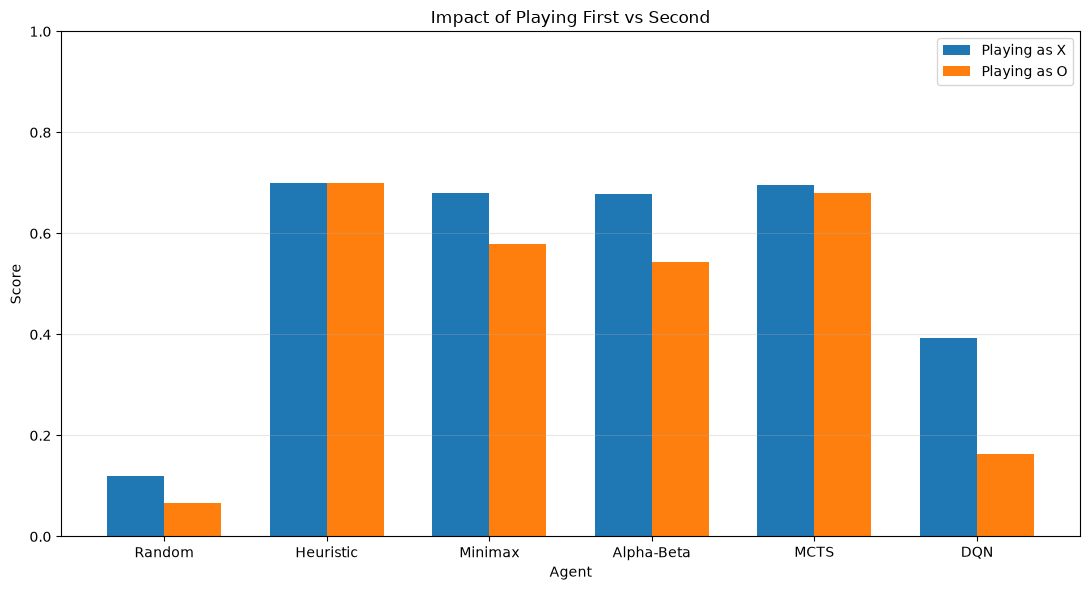

In [12]:
import matplotlib.pyplot as plt

x = np.arange(len(agents))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    position_df["X Score"],
    width,
    label="Playing as X"
)

plt.bar(
    x + width / 2,
    position_df["O Score"],
    width,
    label="Playing as O"
)

plt.xlabel("Agent")
plt.ylabel("Score")
plt.title("Impact of Playing First vs Second")

plt.xticks(x, agents)
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
x_wins = (matches["winner"] == matches["agent_x"]).sum()
o_wins = (matches["winner"] == matches["agent_o"]).sum()
draws = (matches["winner"] == "DRAW").sum()

total = len(matches)

overall_position = pd.DataFrame([
    {
        "Position": "X - First Player",
        "Wins": x_wins,
        "Draws": draws,
        "Losses": o_wins,
        "Win Rate": x_wins / total,
        "Score": (x_wins + 0.5 * draws) / total
    },
    {
        "Position": "O - Second Player",
        "Wins": o_wins,
        "Draws": draws,
        "Losses": x_wins,
        "Win Rate": o_wins / total,
        "Score": (o_wins + 0.5 * draws) / total
    }
])

display(overall_position.round(4))

print("Tổng số trận:", total)
print("X thắng:", x_wins)
print("O thắng:", o_wins)
print("Hòa:", draws)

,Position,Wins,Draws,Losses,Win Rate,Score
0,X - First Player,425,783,292,0.2833,0.5443
1,O - Second Player,292,783,425,0.1947,0.4557


Tổng số trận: 1500
X thắng: 425
O thắng: 292
Hòa: 783


In [14]:
OUTPUT_DIR = r"D:\TTNTNC\TicTacToe_AI\results"

position_df.to_csv(
    OUTPUT_DIR + r"\position_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

overall_position.to_csv(
    OUTPUT_DIR + r"\overall_position_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu thành công:")
print(OUTPUT_DIR + r"\position_analysis.csv")
print(OUTPUT_DIR + r"\overall_position_analysis.csv")

Đã lưu thành công:
D:\TTNTNC\TicTacToe_AI\results\position_analysis.csv
D:\TTNTNC\TicTacToe_AI\results\overall_position_analysis.csv


In [17]:
import inspect
import os
import sys
project_root = r"D:\TTNTNC\TicTacToe_AI"
if project_root not in sys.path:
  sys.path.insert(0, project_root)
import experiments.round_robin as rr

# Hiển thị tham số của hàm
print("THAM SỐ RUN_TOURNAMENT:")
print(inspect.signature(rr.run_tournament))

# Hiển thị phần đầu của hàm
print("\nSOURCE CODE:")
print(inspect.getsource(rr.run_tournament))

THAM SỐ RUN_TOURNAMENT:
(agent_manager=None, games_per_pair=100, seed=42, selected_agents=None)

SOURCE CODE:
def run_tournament(
    agent_manager=None,
    games_per_pair=DEFAULT_GAMES_PER_PAIR,
    seed=DEFAULT_SEED,
    selected_agents=None
):
    """
    Thi đấu vòng tròn giữa các AI.

    Mỗi cặp AI được thi đấu games_per_pair ván.
    Số ván được chia đều giữa hai bên cầm X và O.
    """

    if games_per_pair < 2 or games_per_pair % 2 != 0:
        raise ValueError(
            "games_per_pair phải là số chẵn và >= 2."
        )

    if agent_manager is None:
        agent_manager = AgentManager()

    if selected_agents is None:
        selected_agents = agent_manager.get_agent_names()

    for name in selected_agents:
        if name not in agent_manager.agents:
            raise ValueError(f"Không tìm thấy agent: {name}")

    pairs = list(
        itertools.combinations(selected_agents, 2)
    )

    total_games = len(pairs) * games_per_pair

    match_records = []
    move

In [18]:
import os
import json
import time
import contextlib
import pandas as pd
import numpy as np

from ui.agent_manager import AgentManager

# Import module tournament
import experiments.round_robin as rr

# Cấu hình
SEEDS = [42, 123, 2026, 2027, 9999]
GAMES_PER_PAIR = 20

AGENTS = [
    "Random",
    "Heuristic",
    "Minimax",
    "Alpha-Beta",
    "MCTS",
    "DQN"
]

# Thư mục gốc kết quả
BASE_RESULTS_DIR = r"D:\TTNTNC\TicTacToe_AI\results"
SEED_RESULTS_DIR = os.path.join(
    BASE_RESULTS_DIR,
    "seed_analysis"
)

os.makedirs(SEED_RESULTS_DIR, exist_ok=True)

# Kiểm tra cấu hình
print("Số Agent:", len(AGENTS))
print("Số cặp đấu:", len(AGENTS) * (len(AGENTS) - 1) // 2)
print("Số trận mỗi seed:", 15 * GAMES_PER_PAIR)
print("Số seed:", len(SEEDS))
print("Tổng số trận dự kiến:", 15 * GAMES_PER_PAIR * len(SEEDS))

# Tạo AgentManager
agent_manager = AgentManager()

print("\nDanh sách Agent:")
print(agent_manager.get_agent_names())

print("\nThiết bị:", agent_manager.device)
print("\nThư mục lưu:", SEED_RESULTS_DIR)

Số Agent: 6
Số cặp đấu: 15
Số trận mỗi seed: 300
Số seed: 5
Tổng số trận dự kiến: 1500
Agent Manager initialized!
Device: cuda
Available Agents: ['Random', 'Heuristic', 'Minimax', 'Alpha-Beta', 'MCTS', 'DQN']

Danh sách Agent:
['Random', 'Heuristic', 'Minimax', 'Alpha-Beta', 'MCTS', 'DQN']

Thiết bị: cuda

Thư mục lưu: D:\TTNTNC\TicTacToe_AI\results\seed_analysis


In [19]:
seed_summaries = []

total_start = time.perf_counter()

for seed in SEEDS:

    print("\n" + "=" * 60)
    print(f"BẮT ĐẦU THÍ NGHIỆM SEED = {seed}")
    print("=" * 60)

    # Tạo thư mục riêng cho seed
    current_dir = os.path.join(
        SEED_RESULTS_DIR,
        f"seed_{seed}"
    )

    os.makedirs(current_dir, exist_ok=True)

    # Chuyển thư mục lưu kết quả của tournament
    rr.RESULTS_DIR = current_dir

    # Lưu log riêng
    log_path = os.path.join(
        current_dir,
        "tournament.log"
    )

    start = time.perf_counter()

    with open(log_path, "w", encoding="utf-8") as log_file:
        with contextlib.redirect_stdout(log_file):

            result = rr.run_tournament(
                agent_manager=agent_manager,
                games_per_pair=GAMES_PER_PAIR,
                seed=seed,
                selected_agents=AGENTS
            )

    elapsed = time.perf_counter() - start

    # Ghi nhận kết quả tổng hợp của seed
    for item in result["summary"]:

        seed_summaries.append({
            "Seed": seed,
            "Agent": item["agent"],
            "Wins": item["wins"],
            "Draws": item["draws"],
            "Losses": item["losses"],
            "Games": item["games"],
            "Score": item["score"]
        })

    print(f"Seed {seed} hoàn thành!")
    print(f"Số trận: {len(result['matches'])}")
    print(f"Thời gian: {elapsed:.2f} giây")
    print(f"Kết quả: {current_dir}")

total_elapsed = time.perf_counter() - total_start

print("\n" + "=" * 60)
print("ĐÃ HOÀN THÀNH THÍ NGHIỆM RANDOM SEED")
print("=" * 60)
print("Tổng thời gian:", round(total_elapsed, 2), "giây")
print("Tổng số trận:", len(SEEDS) * 15 * GAMES_PER_PAIR)


BẮT ĐẦU THÍ NGHIỆM SEED = 42
Seed 42 hoàn thành!
Số trận: 300
Thời gian: 801.55 giây
Kết quả: D:\TTNTNC\TicTacToe_AI\results\seed_analysis\seed_42

BẮT ĐẦU THÍ NGHIỆM SEED = 123
Seed 123 hoàn thành!
Số trận: 300
Thời gian: 838.24 giây
Kết quả: D:\TTNTNC\TicTacToe_AI\results\seed_analysis\seed_123

BẮT ĐẦU THÍ NGHIỆM SEED = 2026
Seed 2026 hoàn thành!
Số trận: 300
Thời gian: 851.25 giây
Kết quả: D:\TTNTNC\TicTacToe_AI\results\seed_analysis\seed_2026

BẮT ĐẦU THÍ NGHIỆM SEED = 2027
Seed 2027 hoàn thành!
Số trận: 300
Thời gian: 823.38 giây
Kết quả: D:\TTNTNC\TicTacToe_AI\results\seed_analysis\seed_2027

BẮT ĐẦU THÍ NGHIỆM SEED = 9999
Seed 9999 hoàn thành!
Số trận: 300
Thời gian: 833.54 giây
Kết quả: D:\TTNTNC\TicTacToe_AI\results\seed_analysis\seed_9999

ĐÃ HOÀN THÀNH THÍ NGHIỆM RANDOM SEED
Tổng thời gian: 4147.96 giây
Tổng số trận: 1500


In [20]:
seed_df = pd.DataFrame(seed_summaries)

display(
    seed_df.sort_values(
        ["Agent", "Seed"]
    ).round(4)
)

# Lưu kết quả
seed_summary_path = os.path.join(
    SEED_RESULTS_DIR,
    "seed_summary.csv"
)

seed_df.to_csv(
    seed_summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu:", seed_summary_path)

,Seed,Agent,Wins,Draws,Losses,Games,Score
3,42,Alpha-Beta,25,75,0,100,0.625
9,123,Alpha-Beta,25,75,0,100,0.625
14,2026,Alpha-Beta,26,74,0,100,0.630
20,2027,Alpha-Beta,26,74,0,100,0.630
26,9999,Alpha-Beta,24,76,0,100,0.620
4,42,DQN,13,27,60,100,0.265
10,123,DQN,15,25,60,100,0.275
16,2026,DQN,15,24,61,100,0.270
22,2027,DQN,15,24,61,100,0.270
28,9999,DQN,11,23,66,100,0.225


Đã lưu: D:\TTNTNC\TicTacToe_AI\results\seed_analysis\seed_summary.csv


In [21]:
stability_df = (
    seed_df.groupby("Agent")
    .agg(
        Mean_Score=("Score", "mean"),
        Std_Score=("Score", "std"),
        Min_Score=("Score", "min"),
        Max_Score=("Score", "max"),
        Mean_Wins=("Wins", "mean"),
        Mean_Draws=("Draws", "mean"),
        Mean_Losses=("Losses", "mean")
    )
    .reset_index()
)

stability_df["Score_Range"] = (
    stability_df["Max_Score"]
    - stability_df["Min_Score"]
)

# Xếp hạng theo điểm trung bình
stability_df = stability_df.sort_values(
    "Mean_Score",
    ascending=False
)

display(stability_df.round(4))

# Lưu kết quả
stability_path = os.path.join(
    SEED_RESULTS_DIR,
    "seed_stability.csv"
)

stability_df.to_csv(
    stability_path,
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu:", stability_path)

,Agent,Mean_Score,Std_Score,Min_Score,Max_Score,Mean_Wins,Mean_Draws,Mean_Losses,Score_Range
2,Heuristic,0.699,0.0022,0.695,0.700,39.8,60.2,0.0,0.005
3,MCTS,0.690,0.0087,0.675,0.695,38.0,62.0,0.0,0.020
0,Alpha-Beta,0.626,0.0042,0.620,0.630,25.2,74.8,0.0,0.010
4,Minimax,0.622,0.0130,0.605,0.635,24.4,75.6,0.0,0.030
1,DQN,0.261,0.0204,0.225,0.275,13.8,24.6,61.6,0.050
5,Random,0.102,0.0329,0.080,0.160,3.0,14.4,82.6,0.080


Đã lưu: D:\TTNTNC\TicTacToe_AI\results\seed_analysis\seed_stability.csv


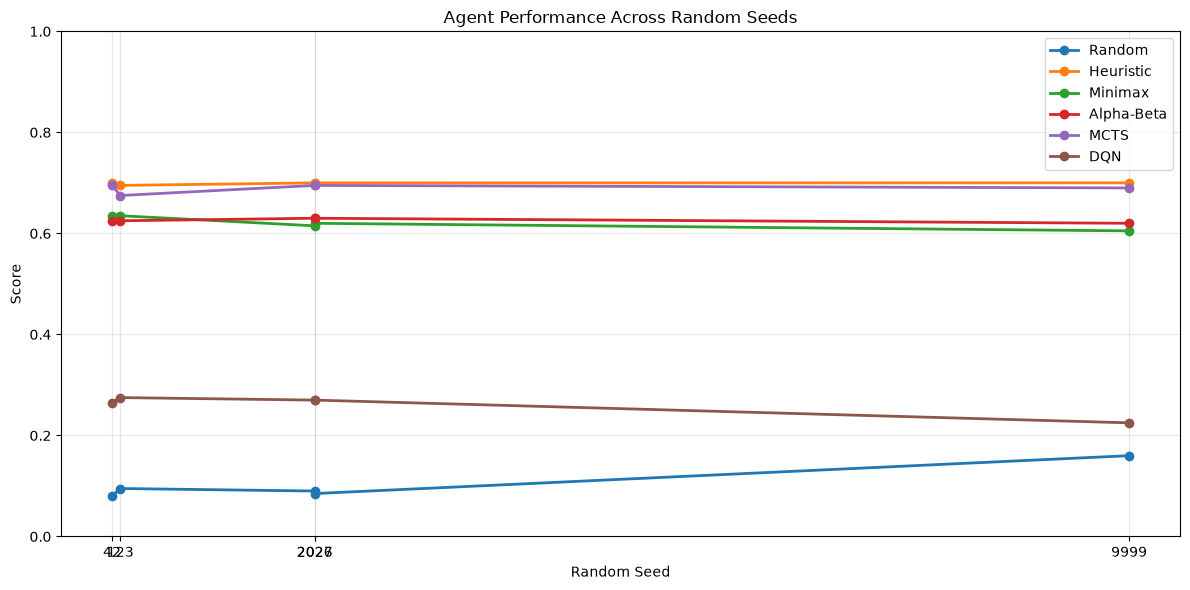

In [22]:
import matplotlib.pyplot as plt

pivot_df = seed_df.pivot(
    index="Seed",
    columns="Agent",
    values="Score"
)

plt.figure(figsize=(12, 6))

for agent in AGENTS:
    plt.plot(
        pivot_df.index,
        pivot_df[agent],
        marker="o",
        linewidth=2,
        label=agent
    )

plt.title("Agent Performance Across Random Seeds")
plt.xlabel("Random Seed")
plt.ylabel("Score")

plt.xticks(SEEDS)
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

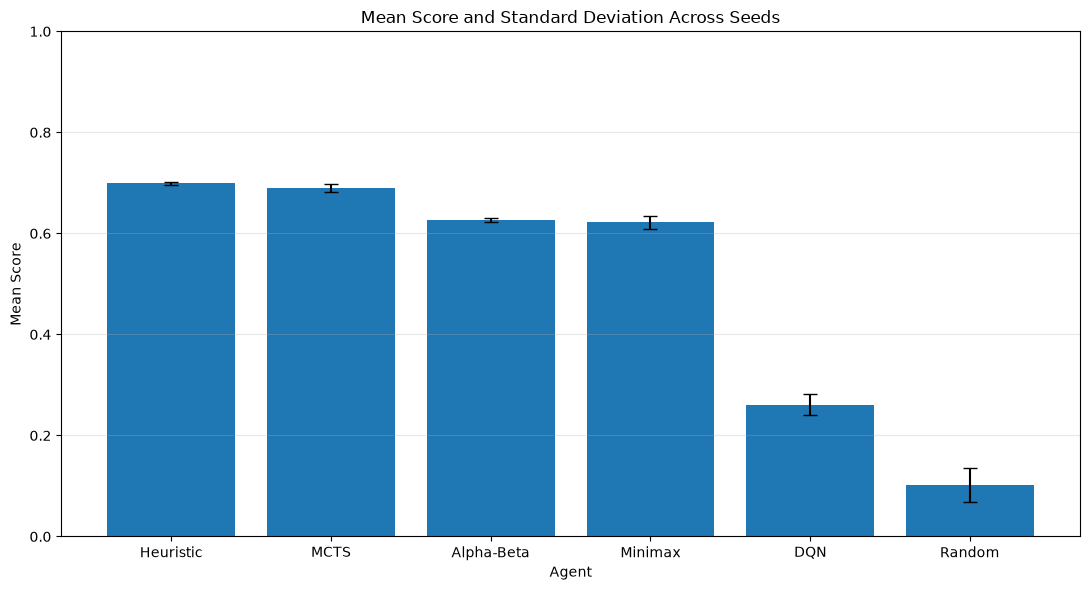

In [23]:
plt.figure(figsize=(11, 6))

plt.bar(
    stability_df["Agent"],
    stability_df["Mean_Score"],
    yerr=stability_df["Std_Score"].fillna(0),
    capsize=5
)

plt.title("Mean Score and Standard Deviation Across Seeds")
plt.xlabel("Agent")
plt.ylabel("Mean Score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from game.game_engine import GameEngine
from agents.minimax_agent import MinimaxAgent
from agents.alphabeta_agent import AlphaBetaAgent

print("Import thành công!")

Import thành công!


In [25]:
import inspect

print("===== MINIMAX =====")
print(inspect.signature(MinimaxAgent))
print(inspect.getsource(MinimaxAgent.__init__))

print("\n===== ALPHA-BETA =====")
print(inspect.signature(AlphaBetaAgent))
print(inspect.getsource(AlphaBetaAgent.__init__))

===== MINIMAX =====
(depth=4, name='Minimax Agent')
    def __init__(self, depth=4, name="Minimax Agent"):

        if not isinstance(depth, (int, np.integer)) or isinstance(depth, bool):
            raise TypeError("Depth must be an integer!")

        if depth < 1:
            raise ValueError("Depth must be greater than or equal to 1!")

        self.name = name
        self.depth = int(depth)

        # Search metrics
        self.nodes_visited = 0
        self.nodes_expanded = 0
        self.decision_time = 0.0
        self.nodes_per_second = 0.0

        # Store latest experiment results
        self.last_search_stats = {}

        self.weights = {
            1: 1,
            2: 10,
            3: 100,
            4: 10000
        }

        self.WIN_SCORE = 1000000


===== ALPHA-BETA =====
(depth=4, name='Alpha-Beta Agent')
    def __init__(self, depth=4, name="Alpha-Beta Agent"):

        # Initialize inherited attributes and validate depth
        super().__init__(depth=dept

In [26]:
minimax = MinimaxAgent(depth=2)
alphabeta = AlphaBetaAgent(depth=2)

print("Minimax stats:")
print(minimax.get_search_stats())

print("\nAlpha-Beta stats:")
print(alphabeta.get_search_stats())

Minimax stats:
{'agent': 'Minimax Agent', 'algorithm': 'Minimax', 'depth': 2, 'nodes_visited': 0, 'nodes_expanded': 0, 'decision_time': 0.0, 'nodes_per_second': 0.0}

Alpha-Beta stats:
{'agent': 'Alpha-Beta Agent', 'algorithm': 'Alpha-Beta', 'depth': 2, 'nodes_visited': 0, 'nodes_expanded': 0, 'decision_time': 0.0, 'nodes_per_second': 0.0, 'pruned_branches': 0, 'cutoffs': 0, 'actions_considered': 0, 'pruning_rate': 0.0}


In [27]:
print("===== MINIMAX SOURCE =====")
print(inspect.getsource(MinimaxAgent))

print("\n===== ALPHA-BETA SOURCE =====")
print(inspect.getsource(AlphaBetaAgent))

===== MINIMAX SOURCE =====
class MinimaxAgent:
    """
    Minimax Agent for Tic-Tac-Toe 4x4.

    Board representation:
         1 = X
        -1 = O
         0 = Empty

    Action:
        (row, col)

    Experimental metrics:
        - nodes_visited
        - nodes_expanded
        - decision_time
        - nodes_per_second
    """

    def __init__(self, depth=4, name="Minimax Agent"):

        if not isinstance(depth, (int, np.integer)) or isinstance(depth, bool):
            raise TypeError("Depth must be an integer!")

        if depth < 1:
            raise ValueError("Depth must be greater than or equal to 1!")

        self.name = name
        self.depth = int(depth)

        # Search metrics
        self.nodes_visited = 0
        self.nodes_expanded = 0
        self.decision_time = 0.0
        self.nodes_per_second = 0.0

        # Store latest experiment results
        self.last_search_stats = {}

        self.weights = {
            1: 1,
            2: 10,
            3:

In [28]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from game.game_engine import GameEngine
from agents.minimax_agent import MinimaxAgent
from agents.alphabeta_agent import AlphaBetaAgent

DEPTHS = [1, 2, 3, 4, 5]
N_STATES = 20

OUTPUT_DIR = r"D:\TTNTNC\TicTacToe_AI\results\depth_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Depth:", DEPTHS)
print("Số trạng thái:", N_STATES)
print("Thư mục lưu:", OUTPUT_DIR)

Depth: [1, 2, 3, 4, 5]
Số trạng thái: 20
Thư mục lưu: D:\TTNTNC\TicTacToe_AI\results\depth_analysis


In [29]:
rng = random.Random(2026)

test_positions = []

for state_id in range(N_STATES):

    game = GameEngine(
        board_size=4,
        win_length=4
    )

    game.reset()

    # Số nước đã đi trước khi lấy trạng thái
    target_plies = rng.randint(3, 7)

    for _ in range(target_plies):

        if game.is_terminal():
            break

        legal_actions = game.legal_actions()

        if not legal_actions:
            break

        action = rng.choice(legal_actions)
        game.step(action)

    # Chỉ lấy trạng thái chưa kết thúc
    if not game.is_terminal():

        test_positions.append({
            "state_id": state_id + 1,
            "plies": target_plies,
            "game": game.clone()
        })

print("Số trạng thái tạo được:", len(test_positions))

for position in test_positions:
    print(
        f"State {position['state_id']:02d} | "
        f"Plies: {position['plies']} | "
        f"Current player: "
        f"{position['game'].get_current_player()}"
    )

assert len(test_positions) == N_STATES, (
    "Không tạo đủ 20 trạng thái. "
    "Hãy kiểm tra GameEngine."
)

Số trạng thái tạo được: 20
State 01 | Plies: 3 | Current player: O
State 02 | Plies: 3 | Current player: O
State 03 | Plies: 7 | Current player: O
State 04 | Plies: 6 | Current player: X
State 05 | Plies: 3 | Current player: O
State 06 | Plies: 6 | Current player: X
State 07 | Plies: 6 | Current player: X
State 08 | Plies: 5 | Current player: O
State 09 | Plies: 7 | Current player: O
State 10 | Plies: 6 | Current player: X
State 11 | Plies: 6 | Current player: X
State 12 | Plies: 6 | Current player: X
State 13 | Plies: 7 | Current player: O
State 14 | Plies: 4 | Current player: X
State 15 | Plies: 6 | Current player: X
State 16 | Plies: 7 | Current player: O
State 17 | Plies: 3 | Current player: O
State 18 | Plies: 7 | Current player: O
State 19 | Plies: 6 | Current player: X
State 20 | Plies: 3 | Current player: O


In [30]:
experiment_records = []

algorithms = {
    "Minimax": MinimaxAgent,
    "Alpha-Beta": AlphaBetaAgent
}

total_runs = len(algorithms) * len(DEPTHS) * len(test_positions)
run_count = 0

for algorithm_name, AgentClass in algorithms.items():

    print("\n" + "=" * 55)
    print("ALGORITHM:", algorithm_name)
    print("=" * 55)

    for depth in DEPTHS:

        print(f"\nĐang chạy Depth = {depth}")

        agent = AgentClass(depth=depth)

        for position in test_positions:

            run_count += 1

            # Tạo bản sao bàn cờ
            game_copy = position["game"].clone()

            # Thực hiện tìm kiếm
            action = agent.choose_action(game_copy)

            # Lấy thống kê
            stats = agent.get_search_stats()

            experiment_records.append({
                "Algorithm": algorithm_name,
                "Depth": depth,
                "State_ID": position["state_id"],
                "Plies": position["plies"],
                "Action": str(action),
                "Nodes_Visited": stats["nodes_visited"],
                "Nodes_Expanded": stats["nodes_expanded"],
                "Decision_Time": stats["decision_time"],
                "Nodes_Per_Second": stats["nodes_per_second"],
                "Pruned_Branches": stats.get(
                    "pruned_branches", 0
                ),
                "Cutoffs": stats.get("cutoffs", 0),
                "Pruning_Rate": stats.get(
                    "pruning_rate", 0
                )
            })

        print(
            f"Hoàn thành Depth {depth} | "
            f"Tiến độ: {run_count}/{total_runs}"
        )

depth_df = pd.DataFrame(experiment_records)

print("\nĐÃ HOÀN THÀNH THÍ NGHIỆM")
print("Tổng lượt tìm kiếm:", len(depth_df))

display(depth_df.head(10))


ALGORITHM: Minimax

Đang chạy Depth = 1
Hoàn thành Depth 1 | Tiến độ: 20/200

Đang chạy Depth = 2
Hoàn thành Depth 2 | Tiến độ: 40/200

Đang chạy Depth = 3
Hoàn thành Depth 3 | Tiến độ: 60/200

Đang chạy Depth = 4
Hoàn thành Depth 4 | Tiến độ: 80/200

Đang chạy Depth = 5
Hoàn thành Depth 5 | Tiến độ: 100/200

ALGORITHM: Alpha-Beta

Đang chạy Depth = 1
Hoàn thành Depth 1 | Tiến độ: 120/200

Đang chạy Depth = 2
Hoàn thành Depth 2 | Tiến độ: 140/200

Đang chạy Depth = 3
Hoàn thành Depth 3 | Tiến độ: 160/200

Đang chạy Depth = 4
Hoàn thành Depth 4 | Tiến độ: 180/200

Đang chạy Depth = 5
Hoàn thành Depth 5 | Tiến độ: 200/200

ĐÃ HOÀN THÀNH THÍ NGHIỆM
Tổng lượt tìm kiếm: 200


,Algorithm,Depth,State_ID,Plies,Action,Nodes_Visited,Nodes_Expanded,Decision_Time,Nodes_Per_Second,Pruned_Branches,Cutoffs,Pruning_Rate
0,Minimax,1,1,3,"(0, 0)",13,13,0.001279,10163.396102,0,0,0.0
1,Minimax,1,2,3,"(3, 0)",13,13,0.001346,9657.529225,0,0,0.0
2,Minimax,1,3,7,"(1, 0)",9,9,0.000843,10671.093319,0,0,0.0
3,Minimax,1,4,6,"(3, 3)",10,10,0.000910,10991.426676,0,0,0.0
4,Minimax,1,5,3,"(3, 0)",13,13,0.001362,9548.292281,0,0,0.0
5,Minimax,1,6,6,"(3, 0)",10,10,0.001855,5391.126223,0,0,0.0
6,Minimax,1,7,6,"(2, 2)",10,10,0.000969,10325.245103,0,0,0.0
7,Minimax,1,8,5,"(1, 2)",11,11,0.001263,8709.422023,0,0,0.0
8,Minimax,1,9,7,"(2, 0)",9,9,0.001143,7871.949595,0,0,0.0
9,Minimax,1,10,6,"(3, 0)",10,10,0.000907,11030.222741,0,0,0.0


In [31]:
depth_summary = (
    depth_df.groupby(["Algorithm", "Depth"])
    .agg(
        Mean_Nodes=("Nodes_Visited", "mean"),
        Median_Nodes=("Nodes_Visited", "median"),
        Mean_Time=("Decision_Time", "mean"),
        Median_Time=("Decision_Time", "median"),
        Max_Time=("Decision_Time", "max"),
        Mean_Nodes_Per_Second=("Nodes_Per_Second", "mean"),
        Mean_Pruning_Rate=("Pruning_Rate", "mean")
    )
    .reset_index()
)

display(depth_summary.round(4))

,Algorithm,Depth,Mean_Nodes,Median_Nodes,Mean_Time,Median_Time,Max_Time,Mean_Nodes_Per_Second,Mean_Pruning_Rate
0,Alpha-Beta,1,10.65,10.0,0.0010,0.0009,0.0011,11095.3925,0.0000
1,Alpha-Beta,2,53.40,47.5,0.0041,0.0036,0.0122,13261.7966,53.7465
2,Alpha-Beta,3,365.45,287.0,0.0276,0.0214,0.0763,13311.4106,36.1736
3,Alpha-Beta,4,1320.50,1114.0,0.0963,0.0815,0.4889,14273.8973,52.9486
4,Alpha-Beta,5,7409.05,5390.5,0.5470,0.3954,1.9973,13957.4256,39.8840
5,Minimax,1,10.65,10.0,0.0011,0.0010,0.0019,10247.4249,0.0000
6,Minimax,2,115.30,100.0,0.0095,0.0081,0.0145,12286.3478,0.0000
7,Minimax,3,1070.20,820.0,0.0909,0.0700,0.1750,12222.3156,0.0000
8,Minimax,4,9029.80,5748.0,0.7867,0.5443,1.7722,11735.3659,0.0000
9,Minimax,5,69778.20,34712.0,5.4180,2.5494,15.3005,13449.3938,0.0000


In [32]:
depth_df.to_csv(
    os.path.join(OUTPUT_DIR, "depth_raw_results.csv"),
    index=False,
    encoding="utf-8-sig"
)

depth_summary.to_csv(
    os.path.join(OUTPUT_DIR, "depth_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu dữ liệu Search Depth!")

Đã lưu dữ liệu Search Depth!


In [33]:
node_comparison = depth_df.pivot_table(
    index=["Depth", "State_ID"],
    columns="Algorithm",
    values="Nodes_Visited"
).reset_index()

node_comparison["Node_Reduction_Percent"] = (
    (
        node_comparison["Minimax"]
        - node_comparison["Alpha-Beta"]
    )
    / node_comparison["Minimax"]
) * 100

reduction_summary = (
    node_comparison.groupby("Depth")
    ["Node_Reduction_Percent"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)

reduction_summary.columns = [
    "Depth",
    "Mean_Reduction",
    "Median_Reduction",
    "Min_Reduction",
    "Max_Reduction"
]

display(reduction_summary.round(2))

,Depth,Mean_Reduction,Median_Reduction,Min_Reduction,Max_Reduction
0,1,0.00,0.00,0.00,0.00
1,2,53.75,59.38,8.79,72.00
2,3,64.01,68.80,0.00,83.78
3,4,83.35,87.42,35.38,94.02
4,5,86.31,89.85,39.48,97.03


In [34]:
action_comparison = depth_df.pivot_table(
    index=["Depth", "State_ID"],
    columns="Algorithm",
    values="Action",
    aggfunc="first"
).reset_index()

action_comparison["Same_Action"] = (
    action_comparison["Minimax"]
    == action_comparison["Alpha-Beta"]
)

action_agreement = (
    action_comparison.groupby("Depth")
    ["Same_Action"]
    .mean()
    .reset_index(name="Agreement_Rate")
)

action_agreement["Agreement_Rate"] *= 100

display(action_agreement.round(2))

,Depth,Agreement_Rate
0,1,100.0
1,2,100.0
2,3,100.0
3,4,100.0
4,5,100.0


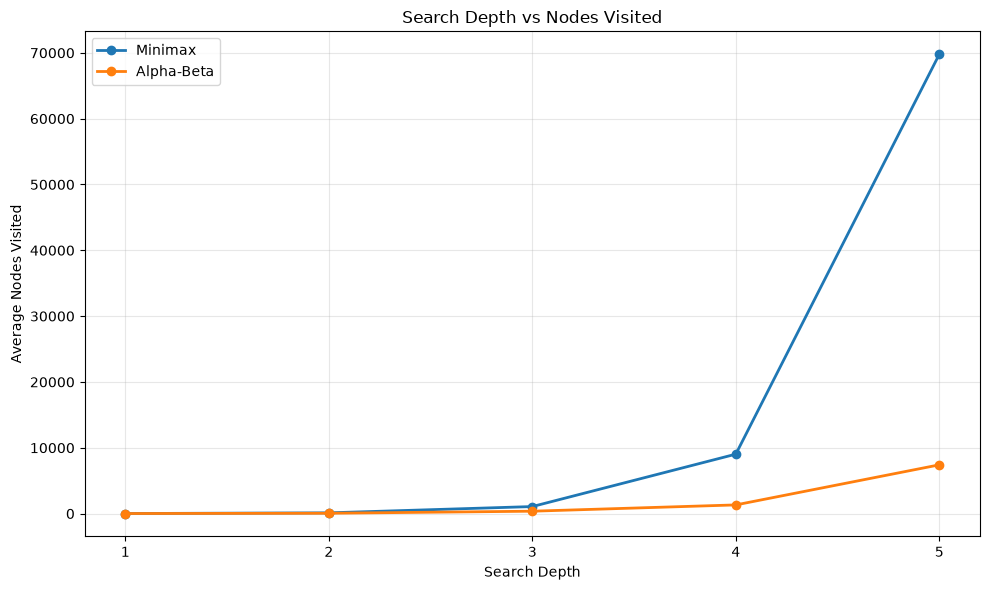

In [35]:
plt.figure(figsize=(10, 6))

for algorithm in ["Minimax", "Alpha-Beta"]:

    data = depth_summary[
        depth_summary["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Depth"],
        data["Mean_Nodes"],
        marker="o",
        linewidth=2,
        label=algorithm
    )

plt.xlabel("Search Depth")
plt.ylabel("Average Nodes Visited")
plt.title("Search Depth vs Nodes Visited")

plt.xticks(DEPTHS)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

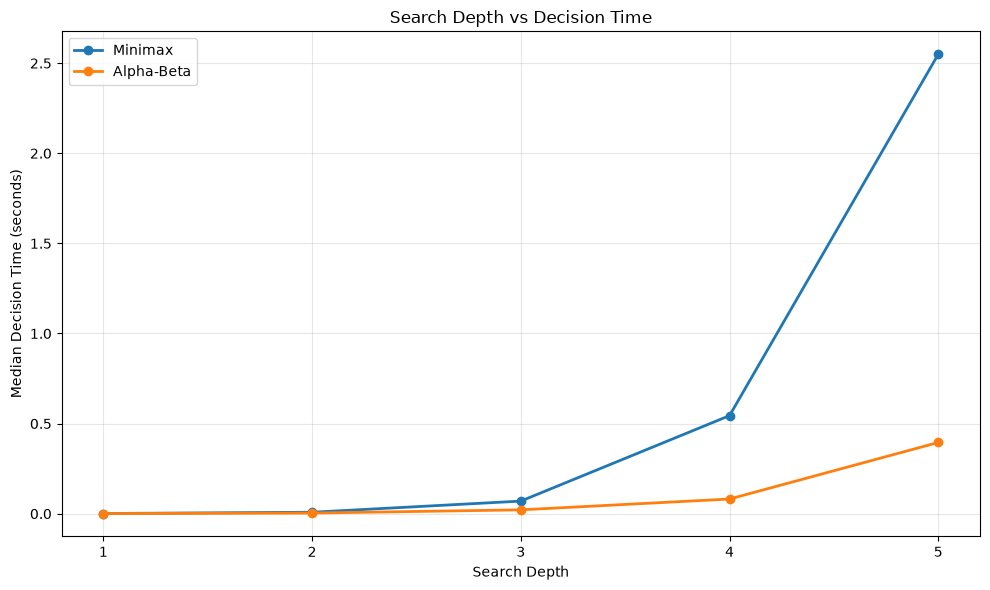

In [36]:
plt.figure(figsize=(10, 6))

for algorithm in ["Minimax", "Alpha-Beta"]:

    data = depth_summary[
        depth_summary["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Depth"],
        data["Median_Time"],
        marker="o",
        linewidth=2,
        label=algorithm
    )

plt.xlabel("Search Depth")
plt.ylabel("Median Decision Time (seconds)")
plt.title("Search Depth vs Decision Time")

plt.xticks(DEPTHS)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

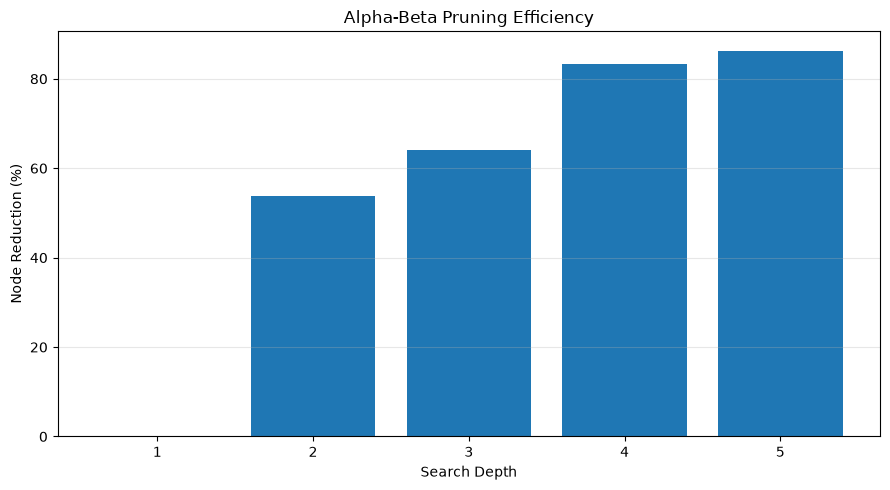

In [37]:
plt.figure(figsize=(9, 5))

plt.bar(
    reduction_summary["Depth"].astype(str),
    reduction_summary["Mean_Reduction"]
)

plt.xlabel("Search Depth")
plt.ylabel("Node Reduction (%)")
plt.title("Alpha-Beta Pruning Efficiency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
with pd.ExcelWriter(
    os.path.join(OUTPUT_DIR, "depth_analysis_report.xlsx")
) as writer:

    depth_df.to_excel(
        writer,
        sheet_name="Raw Results",
        index=False
    )

    depth_summary.to_excel(
        writer,
        sheet_name="Depth Summary",
        index=False
    )

    reduction_summary.to_excel(
        writer,
        sheet_name="Node Reduction",
        index=False
    )

    action_agreement.to_excel(
        writer,
        sheet_name="Action Agreement",
        index=False
    )

print("Đã tạo depth_analysis_report.xlsx")

Đã tạo depth_analysis_report.xlsx
